In [9]:
import geopandas as gpd
import pandas as pd
import mapclassify
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.colors import LogNorm

In [6]:
from pathlib import Path

data_folder = Path(
    "/Users/michelle/Library/CloudStorage/GoogleDrive-mn3369@columbia.edu/My Drive/Fall 2026/Colloquium II/data/IP2LOCATION-LITE-DB11.CSV"
)

for item in data_folder.iterdir():
    print(item.name, "→ folder" if item.is_dir() else "→ file")

IP2LOCATION-LITE-DB11.CSV → file
README_LITE.TXT → file
LICENSE_LITE.TXT → file


In [10]:
path = (
    "/Users/michelle/Library/CloudStorage/"
    "GoogleDrive-mn3369@columbia.edu/My Drive/"
    "Fall 2026/Colloquium II/data/"
    "IP2LOCATION-LITE-DB11.CSV/IP2LOCATION-LITE-DB11.CSV"
)

columns = [
    "ip_start",
    "ip_end",
    "countryID",
    "country",
    "region",
    "city",
    "latitude",
    "longitude",
    "postal_code",
    "time_zone"
]

df = pd.read_csv(
    path,
    header=None,
    names=columns,
    dtype={
        "ip_start": "UInt64",
        "ip_end": "UInt64",
        "postal_code": "string"
    }
)

print(f"IP intervals loaded: {len(df):,}")
df.head()

IP intervals loaded: 2,996,774


,ip_start,ip_end,countryID,country,region,city,latitude,longitude,postal_code,time_zone
0,0,16777215,-,-,-,-,0.000000,0.000000,-,-
1,16777216,16777471,AU,Australia,Queensland,Brisbane,-27.467540,153.028090,4000,+10:00
2,16777472,16778239,CN,China,Fujian,Fuzhou,26.061390,119.306110,350004,+08:00
3,16778240,16779007,AU,Australia,Victoria,Melbourne,-37.814007,144.963171,3000,+10:00
4,16779008,16779263,AU,Australia,Queensland,Warren,-23.500000,150.283330,4702,+10:00


In [11]:
# Convert coordinates to numbers
df["latitude"] = pd.to_numeric(df["latitude"], errors="coerce")
df["longitude"] = pd.to_numeric(df["longitude"], errors="coerce")

# Keep valid coordinates and known countries
valid_rows = (
    df["latitude"].between(-90, 90)
    & df["longitude"].between(-180, 180)
    & df["country"].notna()
    & df["country"].ne("-")
)

map_data = df.loc[valid_rows].copy()

# Count IP addresses in each interval (inclusive endpoints)
map_data["ip_count"] = (
    map_data["ip_end"] - map_data["ip_start"] + 1
)

# Combine intervals that share the same coordinates
locations = (
    map_data
    .groupby(["latitude", "longitude"], as_index=False)
    .agg(
        ip_count=("ip_count", "sum"),
        interval_count=("ip_start", "size")
    )
)

print(f"Valid IP intervals: {len(map_data):,}")
print(f"Unique locations: {len(locations):,}")

locations.head()

Valid IP intervals: 2,988,848
Unique locations: 86,800


,latitude,longitude,ip_count,interval_count
0,-77.846323,166.668235,3328,8
1,-54.800000,-68.300000,22272,36
2,-54.416667,3.366667,1792,4
3,-54.283333,-36.500000,512,1
4,-53.787690,-67.709460,33792,48


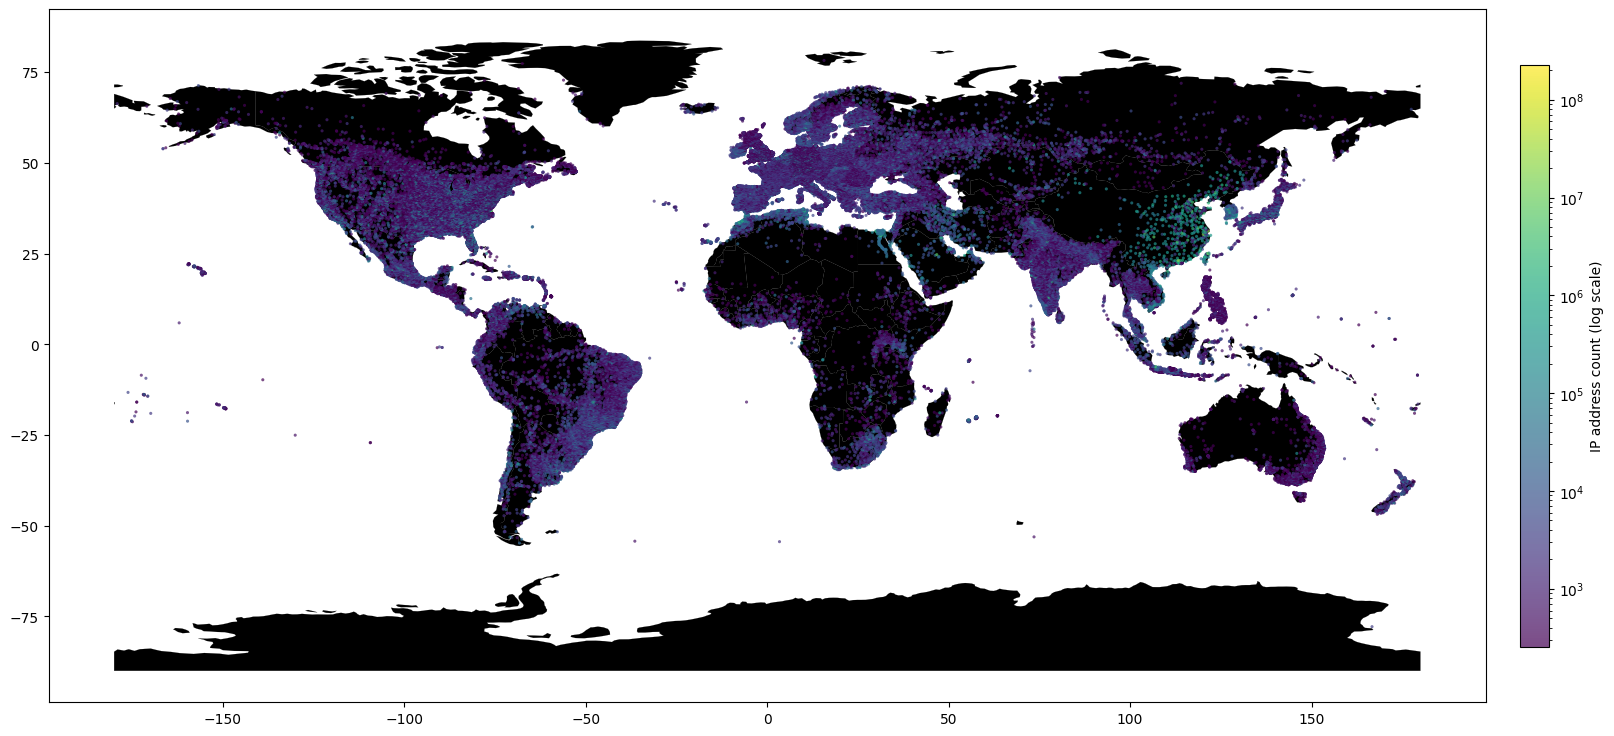

In [ ]:
# Create geographic points
geo_locations = gpd.GeoDataFrame(
    locations.copy(),
    geometry=gpd.points_from_xy(
        locations["longitude"],
        locations["latitude"]
    ),
    crs="EPSG:4326"
)

# Load world boundaries
world_url = (
    "https://raw.githubusercontent.com/nvkelso/"
    "natural-earth-vector/master/geojson/ne_110m_admin_0_countries.geojson"
)

world = gpd.read_file(world_url)

# Draw world map
fig, ax = plt.subplots(figsize=(18, 10))

world.plot(
    ax=ax,
    color="#000000",
    edgecolor="#000000",
    linewidth=0.1
)

points = ax.scatter(
    geo_locations.geometry.x,
    geo_locations.geometry.y,
    c=geo_locations["ip_count"].astype(float),
    cmap="viridis",
    norm=LogNorm(),
    s=5,
    alpha=0.7,
    linewidths=0,
    rasterized=True
)

colorbar = fig.colorbar(points, ax=ax, shrink=0.6, pad=0.02)
colorbar.set_label("IP address count (log scale)" \
"")

ax.set_aspect("equal")
plt.tight_layout()
plt.show()

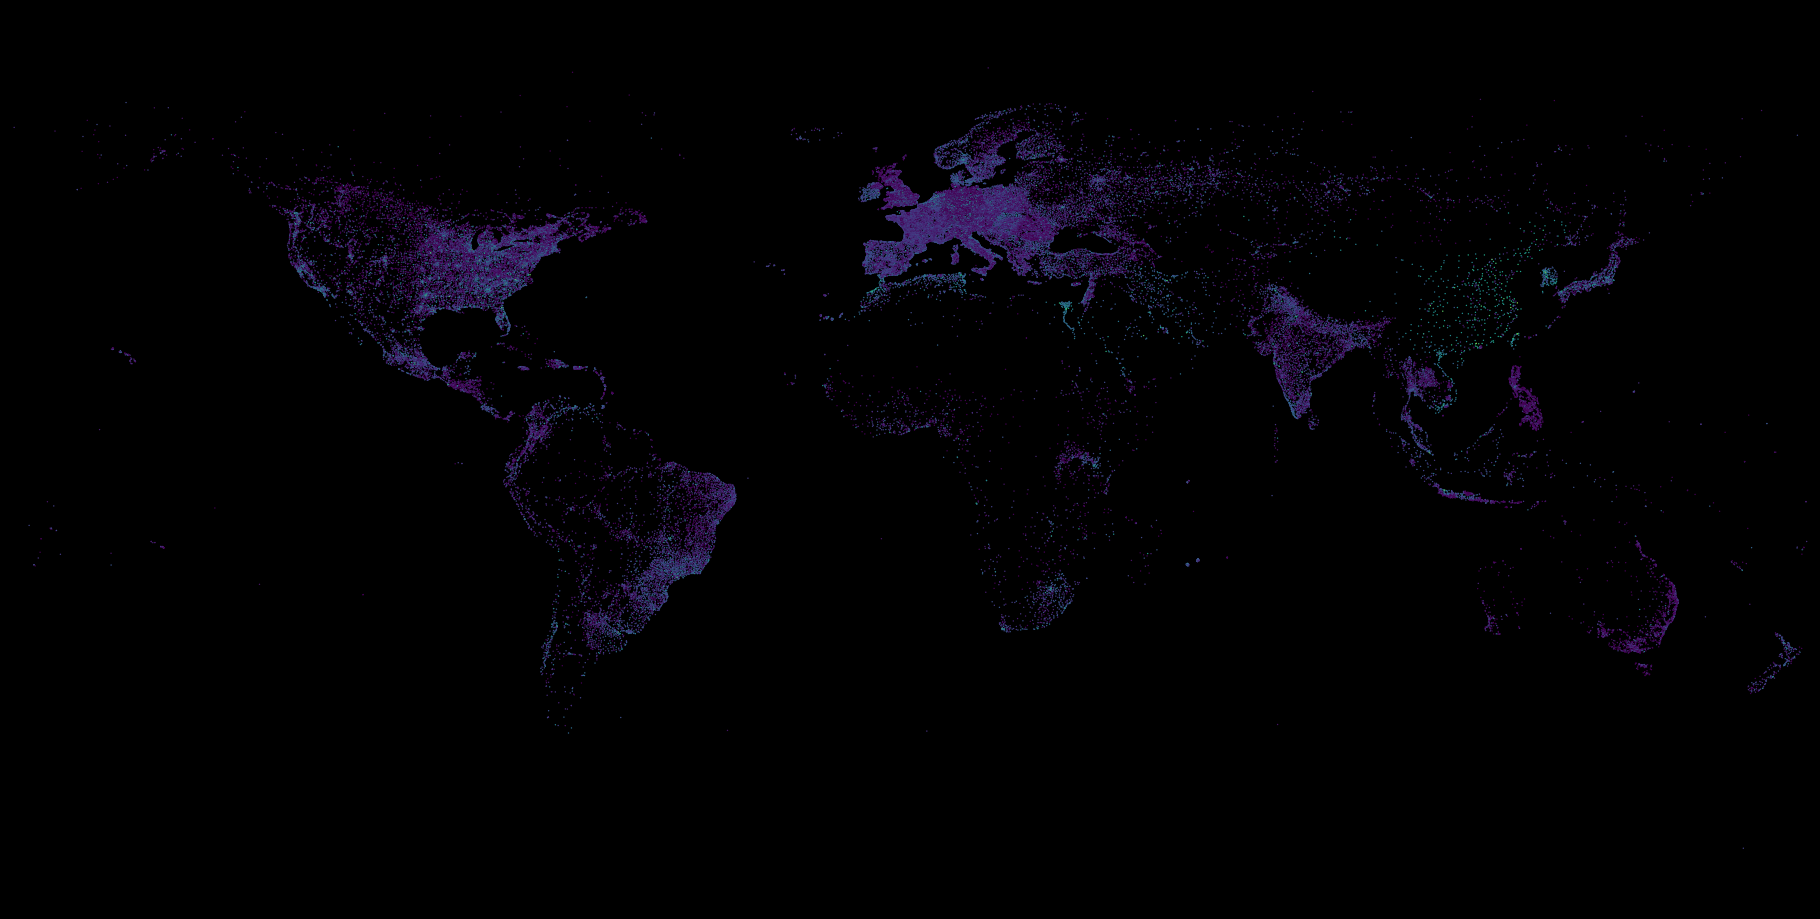

In [25]:
# Create geographic points
geo_locations = gpd.GeoDataFrame(
    locations.copy(),
    geometry=gpd.points_from_xy(
        locations["longitude"],
        locations["latitude"]
    ),
    crs="EPSG:4326"
)

# Load world boundaries
world_url = (
    "https://raw.githubusercontent.com/nvkelso/"
    "natural-earth-vector/master/geojson/ne_110m_admin_0_countries.geojson"
)

world = gpd.read_file(world_url)

# Draw world map
fig, ax = plt.subplots(figsize=(18, 10), facecolor="black")
ax.set_facecolor("black")

world.plot(
    ax=ax,
    color="black",
    edgecolor="black",
    linewidth=0.1
)

ax.scatter(
    geo_locations.geometry.x,
    geo_locations.geometry.y,
    c=geo_locations["ip_count"].astype(float),
    cmap="viridis",
    norm=LogNorm(),
    s=1,
    alpha=1,
    linewidths=0,
    rasterized=True
)

# Set global extent and hide axes
ax.set_xlim(-180, 180)
ax.set_ylim(-90, 90)
ax.set_aspect("equal")
ax.set_axis_off()

plt.tight_layout(pad=0)
plt.show()

In [18]:
from pathlib import Path

output_path = Path("outputs/IpAddresses2026.pdf")
output_path.parent.mkdir(parents=True, exist_ok=True)

fig.savefig(
    output_path,
    dpi=300,
    facecolor="black",
    transparent=False,
    bbox_inches="tight",
    pad_inches=0
)

print(f"Map saved to: {output_path.resolve()}")

Map saved to: /Users/michelle/Desktop/GIT/cdp-mapping-systems/internet/outputs/IpAddresses2026.pdf


In [19]:
from pathlib import Path

output_path = Path("outputs/IpAddresses2026.png")
output_path.parent.mkdir(parents=True, exist_ok=True)

fig.savefig(
    output_path,
    dpi=300,
    facecolor="black",
    transparent=False,
    bbox_inches="tight",
    pad_inches=0
)

print(f"Map saved to: {output_path.resolve()}")

Map saved to: /Users/michelle/Desktop/GIT/cdp-mapping-systems/internet/outputs/IpAddresses2026.png


In [29]:
from pathlib import Path

output_path = Path("outputs/IpAddresses2026.pdf")
output_path.parent.mkdir(parents=True, exist_ok=True)

fig.savefig(
    output_path,
    dpi=300,
    facecolor="black",
    transparent=False,
    bbox_inches="tight",
    pad_inches=0
)

print(f"Map saved to: {output_path.resolve()}")

Map saved to: /Users/michelle/Desktop/GIT/cdp-mapping-systems/internet/outputs/IpAddresses2026.pdf


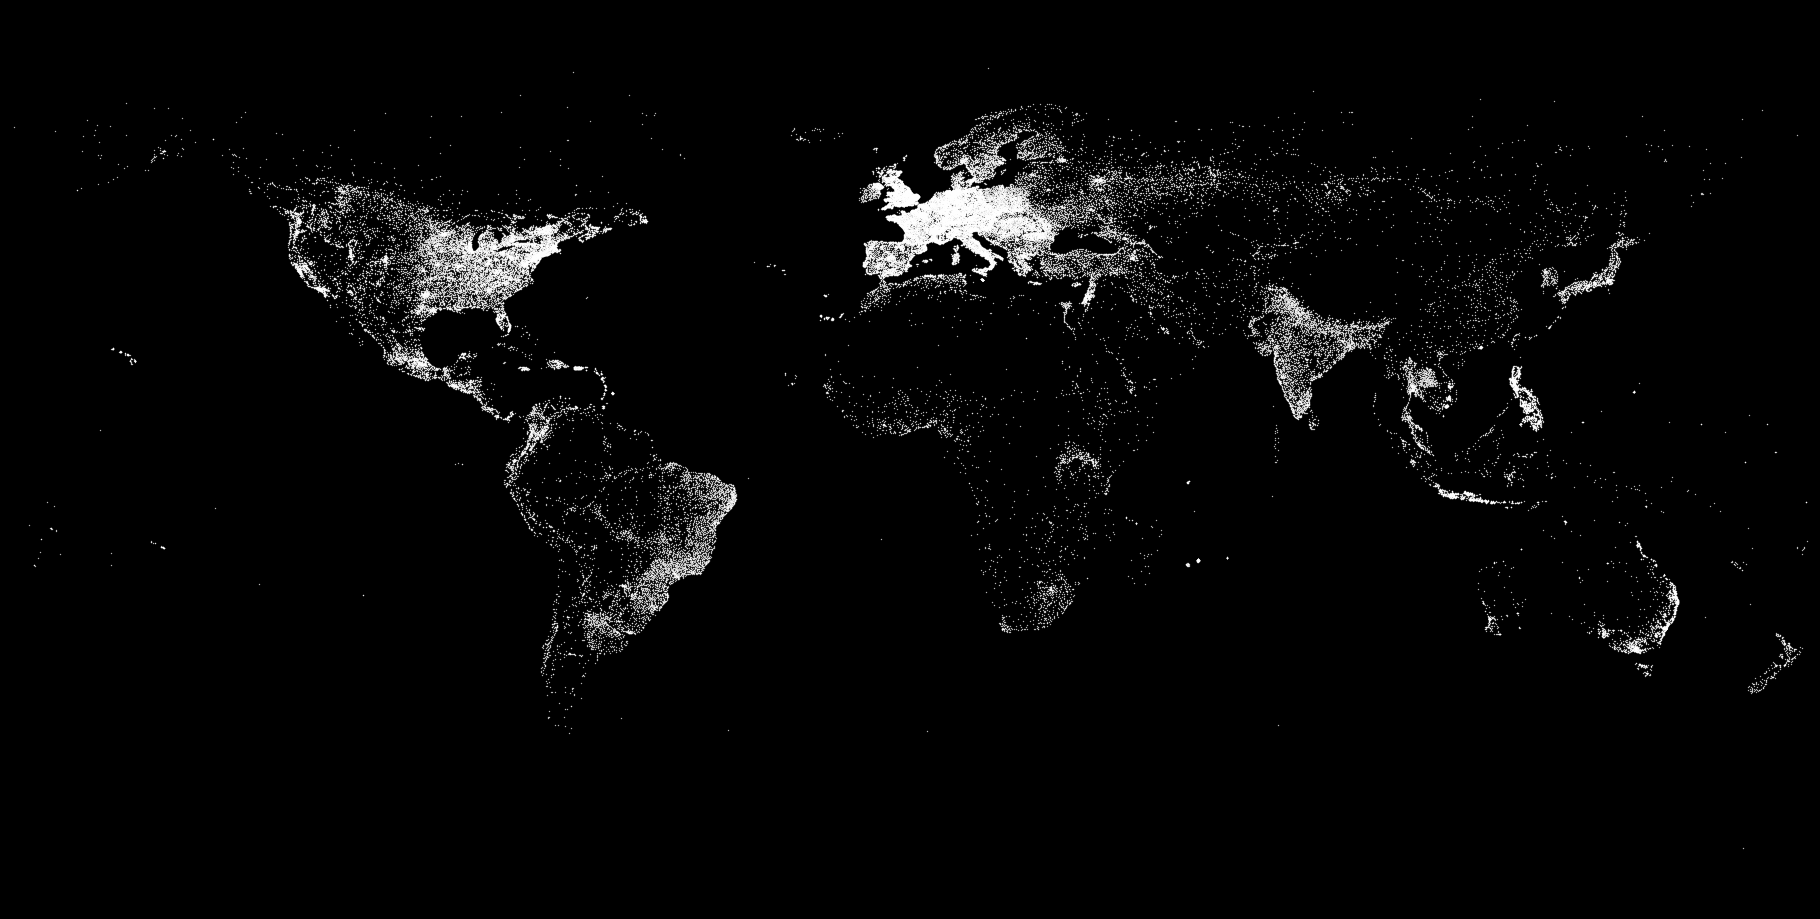

In [30]:
# Create geographic points
geo_locations = gpd.GeoDataFrame(
    locations.copy(),
    geometry=gpd.points_from_xy(
        locations["longitude"],
        locations["latitude"]
    ),
    crs="EPSG:4326"
)

# Load world boundaries
world_url = (
    "https://raw.githubusercontent.com/nvkelso/"
    "natural-earth-vector/master/geojson/ne_110m_admin_0_countries.geojson"
)

world = gpd.read_file(world_url)

# Draw world map
fig, ax = plt.subplots(figsize=(18, 10), facecolor="black")
ax.set_facecolor("black")

world.plot(
    ax=ax,
    color="black",
    edgecolor="black",
    linewidth=0.1
)

ax.scatter(
    geo_locations.geometry.x,
    geo_locations.geometry.y,
    c="white",
    s=1,
    alpha=0.7,
    linewidths=0,
    rasterized=True
)

# Set global extent and hide axes
ax.set_xlim(-180, 180)
ax.set_ylim(-90, 90)
ax.set_aspect("equal")
ax.set_axis_off()

plt.tight_layout(pad=0)
plt.show()

In [31]:
from pathlib import Path

output_path = Path("outputs/IpAddresses2026-bw.png")
output_path.parent.mkdir(parents=True, exist_ok=True)

fig.savefig(
    output_path,
    dpi=300,
    facecolor="black",
    transparent=False,
    bbox_inches="tight",
    pad_inches=0
)

print(f"Map saved to: {output_path.resolve()}")

Map saved to: /Users/michelle/Desktop/GIT/cdp-mapping-systems/internet/outputs/IpAddresses2026-bw.png


In [32]:
from pathlib import Path

output_path = Path("outputs/IpAddresses2026-bw.pdf")
output_path.parent.mkdir(parents=True, exist_ok=True)

fig.savefig(
    output_path,
    dpi=300,
    facecolor="black",
    transparent=False,
    bbox_inches="tight",
    pad_inches=0
)

print(f"Map saved to: {output_path.resolve()}")

Map saved to: /Users/michelle/Desktop/GIT/cdp-mapping-systems/internet/outputs/IpAddresses2026-bw.pdf


In [33]:
# Keep rows with valid coordinates and known city names
valid_rows = (
    df["latitude"].between(-90, 90)
    & df["longitude"].between(-180, 180)
    & df["country"].notna()
    & df["country"].ne("-")
    & df["region"].notna()
    & df["region"].ne("-")
    & df["city"].notna()
    & df["city"].ne("-")
)

city_data = df.loc[valid_rows].copy()

# Count IP addresses in each interval
city_data["ip_count"] = (
    city_data["ip_end"] - city_data["ip_start"] + 1
)

# Aggregate by city, distinguishing cities with the same name
cities = (
    city_data
    .groupby(["country", "region", "city"], as_index=False)
    .agg(
        ip_count=("ip_count", "sum"),
        interval_count=("ip_start", "size"),
        latitude=("latitude", "median"),
        longitude=("longitude", "median")
    )
    .sort_values("ip_count", ascending=False)
    .reset_index(drop=True)
)

print(f"Cities loaded: {len(cities):,}")
cities.head(10)

Cities loaded: 86,771


,country,region,city,ip_count,interval_count,latitude,longitude
0,United States of America,Ohio,Columbus,227488768,3087,39.961380,-82.997749
1,Japan,Tokyo,Tokyo,138925824,46073,35.689497,139.692317
2,United States of America,Washington,Seattle,92444416,10615,47.604309,-122.329845
3,China,Beijing,Beijing,90546688,6248,39.907500,116.397100
4,United Kingdom of Great Britain and Northern I...,England,London,72879616,26867,51.508530,-0.125740
5,United States of America,New York,New York City,61808896,72197,40.713192,-74.006065
6,Korea (the Republic of),Seoul-teukbyeolsi,Seoul,59347200,18592,37.566309,126.977207
7,United States of America,Arizona,Fort Huachuca,54646784,210,31.551184,-110.348334
8,Korea (the Republic of),Gyeonggi-do,Seongnam,43345664,14386,37.420625,127.126715
9,United States of America,Virginia,Ashburn,36453632,9617,39.039474,-77.491809


In [34]:
from pathlib import Path

# Set the website data folder
output_folder = Path(
    "/Users/michelle/Desktop/GIT/"
    "cdp-mapping-systems/internet/_website/data"
)

output_folder.mkdir(parents=True, exist_ok=True)

# Export city data for the web map
output_path = output_folder / "cities.json"

cities.to_json(
    output_path,
    orient="records",
    force_ascii=False,
    indent=2
)

print(f"Cities exported: {len(cities):,}")
print(f"File saved to: {output_path}")

Cities exported: 86,771
File saved to: /Users/michelle/Desktop/GIT/cdp-mapping-systems/internet/_website/data/cities.json
